# Model 5: Extreme Gradient Boosting (XGBoost)

This notebook models the implied volatility surface using XGBoost. Leveraging regularized gradient boosted trees with tree pruning and shrinkage, it achieves state-of-the-art predictive accuracy with compact model memory representation.

**Author:** Sérgio da Cunha Sobral
**Degree:** Master in Financial Mathematics (ISCTE-IUL)
**Supervisor:** Prof.ª Doutora Diana Mendes


### 1. Library Imports


In [1]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

### 2. Core Paths & Configuration


In [2]:
# Core Paths and Configuration
DIR_TRATADOS = "02_data/processed/"
DIR_RESULTADOS = "04_outputs/03_models_metadata/05_model_xgboost/"
DIR_GRAFICOS = "04_outputs/01_figures/08_model_xgboost/"
DIR_TABELAS = "04_outputs/02_tables/05_model_xgboost/"

# Create figures/tables/results directories if they do not exist
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Input data splits
path_universe        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_universo = path_universe
path_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_train = path_inner_train
path_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_inner_tunning = path_inner_tunning
path_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_train_full = path_train_full
path_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")
ficheiro_test_puro = path_test_puro

# Config
# FEATURES = ("log_moneyness", "T", "risk_free_rate", "option_is_call")
FEATURES = ("log_moneyness", "T", "option_is_call")
TARGET   = "iv_teorica"
PRED_COL = "ivs_modelo"


# Model and metadata paths (final artifact names)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "05. XGBoost_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "05. XGBoost_model_inner.meta.json")

BEST_PARAMS = os.path.join(DIR_RESULTADOS, "05. XGBoost_best_params.json")
LINEAR_ADJUST = os.path.join(DIR_RESULTADOS, "05. XGBoost_linear_adjust.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "05. XGBoost_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "05. XGBoost_model.meta.json")

### 3. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


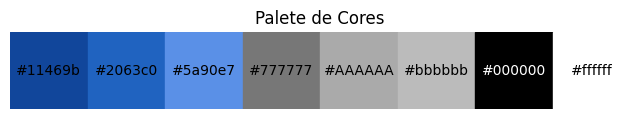

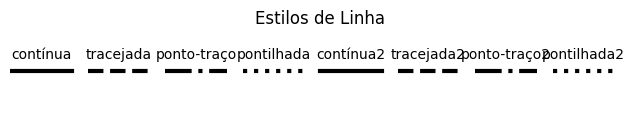

In [3]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"

# Preview loaded color palette and line styles
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    show_colors(COLOR_PALETTE)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    show_line_styles(LINE_STYLES)

### 4. Data Ingestion (Train, Tuning, and Test Splits)


In [4]:
# Load parquet dataset splits
df_inner_train = pd.read_parquet(path_inner_train)
df_inner_tunning = pd.read_parquet(path_inner_tunning)
df_train_full = pd.read_parquet(path_train_full)
df_test_puro = pd.read_parquet(path_test_puro)

# Initial verification of split dimensions
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

### 5. Feature Selection & Architecture Setup


In [5]:
# --- Best params fixados (corrida #5) ---
XGB_BEST_PARAMS = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    max_depth=5,
    min_child_weight=5,
    gamma=0.05625268880566674,
    subsample=0.7050058636738239,
    colsample_bytree=0.6946421476297646,
    learning_rate=0.03472942428328025,
    reg_lambda=4.383497437114556,
    reg_alpha=0.8137436541638764,
    n_estimators=1600,
    n_jobs=-1,
    # coerência XGBoost 2.x
    tree_method="hist",
    device="cuda",   # switch to "cpu" if GPU is unavailable
)

def build_xgb_best(params_override: dict | None = None, use_gpu: bool = True) -> XGBRegressor:
    p = dict(XGB_BEST_PARAMS)
    if params_override: p.update(params_override)
    p["device"] = "cuda" if use_gpu else "cpu"
    p["tree_method"] = "hist"
    p.pop("predictor", None)
    return XGBRegressor(**p)

def eval_metrics(y_true, y_pred):
    return {
        "RMSE": float(root_mean_squared_error(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
    }

def _prep_xy(df, cols, target):
    X = df[list(cols)].astype({c: ("int8" if c=="option_is_call" else "float32") for c in cols})
    y = df[target].astype("float32")
    return X.values, y.values

def fit_and_eval_xgb(train_df, val_df, cols, target="iv_teorica", clip_pred=True, lo=1e-4, hi=2.0, use_gpu=True):
    xgb = build_xgb_best(use_gpu=use_gpu)
    Xtr, ytr = _prep_xy(train_df, cols, target)
    Xva, yva = _prep_xy(val_df,   cols, target)
    xgb.fit(Xtr, ytr, verbose=False)
    pred = xgb.predict(Xva).astype("float32")
    if clip_pred:
        pred = np.clip(pred, lo, hi)
    return eval_metrics(yva, pred), xgb

def compare_sets_xgb(train_df, val_df, base_cols, plus_cols, label, target="iv_teorica", use_gpu=True):
    m_base, _ = fit_and_eval_xgb(train_df, val_df, base_cols, target=target, use_gpu=use_gpu)
    m_plus, _ = fit_and_eval_xgb(train_df, val_df, plus_cols, target=target, use_gpu=use_gpu)
    out = {
        "label": label,
        "RMSE_BASE": m_base["RMSE"], "R2_BASE": m_base["R2"],
        "RMSE_PLUS": m_plus["RMSE"], "R2_PLUS": m_plus["R2"],
        "Delta_RMSE": m_plus["RMSE"] - m_base["RMSE"],
        "Delta_R2":   m_plus["R2"]   - m_base["R2"],
    }
    print(label, "→",
          {"RMSE_BASE": out["RMSE_BASE"], "RMSE_PLUS": out["RMSE_PLUS"], "Delta_RMSE": out["Delta_RMSE"],
           "R2_BASE": out["R2_BASE"], "R2_PLUS": out["R2_PLUS"], "Delta_R2": out["Delta_R2"]})
    return out

# =======================
# Testes equivalentes aos do RF
# =======================
results_xgb = []

# Test 1: (LM,T,r) vs (LM,T,r,is_call)
results_xgb.append(compare_sets_xgb(
    df_inner_train, df_inner_tunning,
    base_cols=("log_moneyness", "T", "risk_free_rate"),
    plus_cols=("log_moneyness", "T", "risk_free_rate", "option_is_call"),
    label="XGB | LM,T,r  vs  LM,T,r,is_call",
    target="iv_teorica", use_gpu=True
))

# Test 2: (LM,T,is_call) vs (LM,T,r,is_call)
results_xgb.append(compare_sets_xgb(
    df_inner_train, df_inner_tunning,
    base_cols=("log_moneyness", "T", "option_is_call"),
    plus_cols=("log_moneyness", "T", "risk_free_rate", "option_is_call"),
    label="XGB | LM,T,is_call  vs  LM,T,r,is_call",
    target="iv_teorica", use_gpu=True
))

# Test 3: (LM,T) vs (LM,T,is_call)
results_xgb.append(compare_sets_xgb(
    df_inner_train, df_inner_tunning,
    base_cols=("log_moneyness", "T"),
    plus_cols=("log_moneyness", "T", "option_is_call"),
    label="XGB | LM,T  vs  LM,T,is_call",
    target="iv_teorica", use_gpu=True
))

# Tabular summary
summary_xgb = pd.DataFrame(results_xgb)[[
    "label", "RMSE_BASE", "RMSE_PLUS", "Delta_RMSE", "R2_BASE", "R2_PLUS", "Delta_R2"
]]
display(summary_xgb)


c:\Users\sergi\Desktop\Tese - IVS with ML Techniques\venv_tese\Lib\site-packages\xgboost\core.py:729: UserWarning: [11:48:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGB | LM,T,r  vs  LM,T,r,is_call → {'RMSE_BASE': 0.045764729380607605, 'RMSE_PLUS': 0.04501715674996376, 'Delta_RMSE': -0.0007475726306438446, 'R2_BASE': 0.8666373491287231, 'R2_PLUS': 0.8709588050842285, 'Delta_R2': 0.004321455955505371}
XGB | LM,T,is_call  vs  LM,T,r,is_call → {'RMSE_BASE': 0.03517813980579376, 'RMSE_PLUS': 0.04501715674996376, 'Delta_RMSE': 0.009839016944169998, 'R2_BASE': 0.9212014675140381, 'R2_PLUS': 0.8709588050842285, 'Delta_R2': -0.05024266242980957}
XGB | LM,T  vs  LM,T,is_call → {'RMSE_BASE': 0.06311020255088806, 'RMSE_PLUS': 0.03517813980579376, 'Delta_RMSE': -0.0279320627450943, 'R2_BASE': 0.7463870048522949, 'R2_PLUS': 0.9212014675140381, 'Delta_R2': 0.17481446266174316}


,label,RMSE_BASE,RMSE_PLUS,Delta_RMSE,R2_BASE,R2_PLUS,Delta_R2
0,"XGB | LM,T,r vs LM,T,r,is_call",0.045765,0.045017,-0.000748,0.866637,0.870959,0.004321
1,"XGB | LM,T,is_call vs LM,T,r,is_call",0.035178,0.045017,0.009839,0.921201,0.870959,-0.050243
2,"XGB | LM,T vs LM,T,is_call",0.063110,0.035178,-0.027932,0.746387,0.921201,0.174814


### 5. Modeling Setup & Pre-estimation Checks


In [6]:
# 1) Basic validation checks
def _basic_checks(df, features, target):
    cols = list(features) + [target]
    missing_cols = [c for c in cols if c not in df.columns]
    if missing_cols: raise ValueError(f"Missing required columns: {missing_cols}")

    sub = df[cols]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        raise ValueError(f"NaNs detected in feature columns: {nan_counts[nan_counts>0].to_dict()}")

    inf_detail = {}
    for c in cols:
        v = sub[c].to_numpy()
        if not np.isfinite(v).all():
            inf_detail[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
    if inf_detail:
        raise ValueError(f"Non-finite values detected: {inf_detail}")
    return sub



# ---------------------------------------------------------------------
# 2) Dtype conversion and sampling utilities (RAM-safe)
def _prepare_xy(df: pd.DataFrame, features: Iterable[str], target: str):
    # Efficient casting to save RAM
    df2 = df.copy()
    for c in features:
        if c == "option_is_call":
            df2[c] = df2[c].astype("int8")
        else:
            df2[c] = df2[c].astype("float32")

    X = df2[list(features)].values 
    y = df2[target].astype("float32").values  
    return X, y

def _make_bins(df: pd.DataFrame, lm_col="log_moneyness", t_col="T", n_lm=30, n_t=12):
    lm_bins = np.linspace(df[lm_col].min(), df[lm_col].max(), n_lm+1)
    t_bins  = np.linspace(df[t_col].min(),  df[t_col].max(),  n_t+1)
    return lm_bins, t_bins

def balanced_sample(df, max_per_bin=5000, lm_col="log_moneyness", t_col="T"):
    df = df.copy()
    lm_q = np.quantile(df[lm_col].values, np.linspace(0, 1, 31))
    t_q  = np.quantile(df[t_col].values,  np.linspace(0, 1, 13))
    lm_edges = np.unique(lm_q)
    t_edges  = np.unique(t_q)
    if lm_edges.size < 3:
        lm_edges = np.linspace(df[lm_col].min(), df[lm_col].max(), 31)
    if t_edges.size < 3:
        t_edges  = np.linspace(df[t_col].min(),  df[t_col].max(),  13)

    lm_cat = pd.cut(df[lm_col], bins=lm_edges, include_lowest=True, right=False)
    t_cat  = pd.cut(df[t_col],  bins=t_edges,  include_lowest=True, right=False)
    df["_lm_bin"] = lm_cat.cat.codes
    df["_t_bin"]  = t_cat.cat.codes

    out = (df.loc[(df["_lm_bin"]>=0) & (df["_t_bin"]>=0)]
             .groupby(["_lm_bin","_t_bin"], group_keys=False)
             .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
             .drop(columns=["_lm_bin","_t_bin"]))
    return out



# ---------------------------------------------------------------------
# ======================================
# 05 — XGBoost (model #5)
# ======================================

from __future__ import annotations
import os, json, joblib, numpy as np, pandas as pd
from typing import Iterable, Tuple
from datetime import datetime, timezone

from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

# ---------------------------------------------------------------------
# 3) Base model construction (GPU/CPU)
def build_xgb(params: dict | None = None, use_gpu: bool = True) -> XGBRegressor:
    base = dict(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        reg_alpha=0.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist",                 # <- SEMPRE 'hist'
        device=("cuda" if use_gpu else "cpu"),  # <- e aqui escolhes GPU/CPU
    )
    if params:
        base.update(params)
        if "tree_method" in base and base["tree_method"] != "hist":
            base["tree_method"] = "hist"
    return XGBRegressor(**base)


# ---------------------------------------------------------------------
# 4) Tuning (random search simples + early stopping)
def _rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    diff = (y_true - y_pred).astype("float64")
    return float(np.sqrt(np.mean(diff * diff)))

def sample_param_space(n_samples: int, rng: int = 42) -> list[dict]:
    import random
    rnd = random.Random(rng)
    
    # run 1
    # n_choices = [400, 800, 1200, 1600, 2000]

    # run 2: refined search around prior best
    # n_choices = [400, 800, 1200, 1600, 2000, 2400]

    # run 3: refined grid
    n_choices = [1600, 2000, 2400, 3000]

    # run 4: (fine-grained grid)
    # n_choices = [1600, 1800, 2000, 2200, 2400, 2600]

    out = []
    for _ in range(n_samples):
        cfg = {
            # run 1
            # "max_depth":        rnd.choice([4,5,6,7,8,9,10]),
            # "min_child_weight": rnd.choice([1,2,3,5,7,10]),
            # "gamma":            rnd.uniform(0.0, 0.5),
            # "subsample":        rnd.uniform(0.6, 1.0),
            # "colsample_bytree": rnd.uniform(0.6, 1.0),
            # "learning_rate":    rnd.uniform(0.01, 0.15),
            # "reg_lambda":       rnd.uniform(0.0, 5.0),
            # "reg_alpha":        rnd.uniform(0.0, 2.0),
            # "n_estimators":     rnd.choice(n_choices),  # <- now tuning this as well

            # run 2: refined search around prior best
            # capacidade contida (o best foi depth=4)
            # "max_depth":        rnd.choice([4, 5, 6]),
            # "min_child_weight": rnd.choice([2, 3, 5, 7]),
            # # more conservative splits
            # "gamma":            rnd.uniform(0.00, 0.20),
            # # estocasticidade (ligeiramente acima do best)
            # "subsample":        rnd.uniform(0.70, 1.00),
            # "colsample_bytree": rnd.uniform(0.70, 1.00),
            # # Lower learning rate (offset by more trees)
            # "learning_rate":    rnd.uniform(0.020, 0.060),
            # "reg_lambda":       rnd.uniform(0.50, 2.50),
            # "reg_alpha":        rnd.uniform(0.00, 0.50),
            # "n_estimators":     rnd.choice(n_choices),

            # run 3: (refined grid)
            "max_depth":        rnd.choice([3, 4, 5]),
            "min_child_weight": rnd.choice([5, 7, 9, 11]),
            "gamma":            rnd.uniform(0.05, 0.30),
            "subsample":        rnd.uniform(0.65, 0.85),
            "colsample_bytree": rnd.uniform(0.65, 0.85),
            "learning_rate":    rnd.uniform(0.020, 0.040),
            "reg_lambda":       rnd.uniform(1.0, 6.0),
            "reg_alpha":        rnd.uniform(0.10, 0.90),
            "n_estimators":     rnd.choice(n_choices),

            # run 4: (fine-grained grid)
            # "max_depth":        rnd.choice([4, 5, 6]),
            # "min_child_weight": rnd.choice([5, 7, 9, 11]),
            # "gamma":            rnd.uniform(0.03, 0.15),
            # "subsample":        rnd.uniform(0.62, 0.82),
            # "colsample_bytree": rnd.uniform(0.62, 0.82),
            # "learning_rate":    rnd.uniform(0.022, 0.045),
            # "reg_lambda":       rnd.uniform(1.5, 6.5),
            # "reg_alpha":        rnd.uniform(0.20, 1.10),
            # "n_estimators":     rnd.choice(n_choices),

        }
        out.append(cfg)
    return out

def tune_xgb(
    df_inner_train: pd.DataFrame,
    df_inner_tunning: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_iter: int = 40,
    use_balanced_sample: bool = True,
    max_per_bin: int = 5000,
    random_state: int = 42,
    use_gpu: bool = True,
    pred_col: str = "ivs_modelo",
) -> tuple[dict, int, pd.DataFrame, pd.DataFrame]:
    """
    Random search SEM early stopping:
      - treino: amostra balanceada de inner_train (ou o próprio inner_train)
      - validação: inner_tunning
    Retorna: (best_params, best_iteration (== n_estimators-1), df_inner_train_pred, df_inner_tunning_pred)
    """
    _basic_checks(df_inner_train, features, target)
    _basic_checks(df_inner_tunning, features, target)

    # balanced sample to accelerate grid search
    train_df = balanced_sample(df_inner_train, max_per_bin=max_per_bin) if use_balanced_sample else df_inner_train

    X_tr_s, y_tr_s = _prepare_xy(train_df,        features, target)
    X_in,  y_in    = _prepare_xy(df_inner_train,  features, target)
    X_va,  y_va    = _prepare_xy(df_inner_tunning,features, target)

    base_params = dict(objective="reg:squarederror", eval_metric="rmse")
    cand_list = sample_param_space(n_iter, rng=random_state)

    best = dict(params=None, best_rmse=np.inf, model=None)
    for i, cand in enumerate(cand_list, 1):
        # evitar paralelismo aninhado
        params_i = {**base_params, **cand, "n_jobs": 1}
        # build model (GPU/CPU according to flag)
        model_i = build_xgb(params=params_i, use_gpu=use_gpu)
        model_i.fit(X_tr_s, y_tr_s, verbose=False)

        # avalia na validação
        y_va_hat = model_i.predict(X_va).astype("float32")
        y_va_hat = np.clip(y_va_hat, 1e-4, 2.0)
        rmse_va = _rmse(y_va, y_va_hat)

        if rmse_va < best["best_rmse"]:
            best.update(params=params_i, best_rmse=rmse_va, model=model_i)

    # best hyperparameters (clear n_jobs=1 for final training)
    best_params = dict(best["params"])
    best_params["n_jobs"] = -1

    # define "best_iteration" to maintain pipeline compatibility
    best_iteration = int(best_params.get("n_estimators", 1)) - 1

    # Refit on full inner_train using best parameters
    best_refit = build_xgb(best_params, use_gpu=use_gpu)
    best_refit.fit(X_in, y_in, verbose=False)

    # Predictions (clip only on predictions)
    y_hat_in = np.clip(best_refit.predict(X_in).astype("float32"), 1e-4, 2.0)
    y_hat_va = np.clip(best_refit.predict(X_va).astype("float32"), 1e-4, 2.0)

    df_inner_train_pred   = df_inner_train.copy()
    df_inner_tunning_pred = df_inner_tunning.copy()
    df_inner_train_pred[pred_col]   = y_hat_in
    df_inner_tunning_pred[pred_col] = y_hat_va

    return best_params, best_iteration, df_inner_train_pred, df_inner_tunning_pred



# ---------------------------------------------------------------------
# 5) Final training
def train_xgb(
    df_train_full: pd.DataFrame,
    features: Iterable[str],
    target: str,
    best_params: dict | None = None,
    best_iteration: int | None = None,
    use_gpu: bool = True,
    return_in_sample_pred: bool = True,
    pred_col: str = "ivs_modelo",
) -> tuple[XGBRegressor, dict, pd.DataFrame | None]:
    """
    Treina XGBRegressor em train_full.
    - If best_iteration is provided: set n_estimators = best_iteration (+1 for safety).
    - If no best_params available: use robust defaults.
    """
    _basic_checks(df_train_full, features, target)
    X_tr, y_tr = _prepare_xy(df_train_full, features, target)

    params = dict(best_params) if best_params else {}
    if best_iteration is not None:
        params["n_estimators"] = int(best_iteration) + 1
        # optional +10% margin:
        params["n_estimators"] = int(max(params["n_estimators"], round((best_iteration + 1) * 1.10)))

    xgb = build_xgb(params, use_gpu=use_gpu)
    xgb.fit(X_tr, y_tr, verbose=False)

    meta = {
        "model_type": "XGBRegressor",
        "features": list(features),
        "target": target,
        "n_obs": int(X_tr.shape[0]),
        "params": xgb.get_params(),
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df_train_full["quote_date"].min()) if "quote_date" in df_train_full.columns else None,
        "date_max": str(df_train_full["quote_date"].max()) if "quote_date" in df_train_full.columns else None,
        "best_iteration": int(best_iteration) if best_iteration is not None else None,
    }

    df_train_pred = None
    if return_in_sample_pred:
        y_hat_tr = xgb.predict(X_tr).astype("float32")
        y_hat_tr = np.clip(y_hat_tr, 1e-4, 2.0)
        df_train_pred = df_train_full.copy()
        df_train_pred[pred_col] = y_hat_tr

    return xgb, meta, df_train_pred


# ---------------------------------------------------------------------
# 6) Model application
def apply_xgb_model(
    df: pd.DataFrame,
    model: XGBRegressor,
    features: Iterable[str],
    pred_col: str = "ivs_modelo",
    clip_pred: bool = True,
    clip_min: float = 1e-4,
    clip_max: float = 2.0,
) -> pd.DataFrame:
    faltam = [c for c in features if c not in df.columns]
    if faltam:
        raise ValueError(f"Missing required columns: {faltam}")
    X, _ = _prepare_xy(df.assign(__y=0.0), features, "__y")
    y_hat = model.predict(X).astype("float32")
    if clip_pred:
        y_hat = np.clip(y_hat, clip_min, clip_max)
    out = df.copy()
    out[pred_col] = y_hat
    return out


# ---------------------------------------------------------------------
# 7) Importâncias
def xgb_importances(
    model: XGBRegressor,
    df_ref: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_repeats: int = 5,
    max_rows: int | None = 200_000,   # <- novo
) -> pd.DataFrame:
    feats = list(features)

    booster = model.get_booster()
    gain_map = booster.get_score(importance_type="gain")
    gain_vals = [gain_map.get(f"f{i}", 0.0) for i in range(len(feats))]

    # Subsample for permutation importance (speeds up massive datasets)
    ref = df_ref
    if (max_rows is not None) and (len(ref) > max_rows):
        ref = ref.sample(max_rows, random_state=42)

    X_ref, y_ref = _prepare_xy(ref, feats, target)
    perm = permutation_importance(model, X_ref, y_ref, n_repeats=n_repeats, random_state=42, n_jobs=-1)

    df_imp = pd.DataFrame({
        "feature": feats,
        "gain_importance": gain_vals,
        "permutation_importance": perm.importances_mean,
        "permutation_std": perm.importances_std,
    }).sort_values(["permutation_importance", "gain_importance"], ascending=False).reset_index(drop=True)

    return df_imp



# ---------------------------------------------------------------------
# 8) IO utilities for optimal parameters
def save_best_params(best_params: dict, best_iteration: int | None, best_path: str):
    payload = dict(best_params=best_params, best_iteration=best_iteration)
    with open(best_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2)

def load_best_params(best_path: str) -> tuple[dict | None, int | None]:
    if not os.path.exists(best_path):
        return None, None
    with open(best_path, "r", encoding="utf-8") as f:
        d = json.load(f)
    return d.get("best_params"), d.get("best_iteration")



# ---------------------------------------------------------------------
# 9) Save / Load model
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

### 7. Hyperparameter Tuning & Validation (inner_tunning)


In [7]:
# --- 1) TUNING em inner (random search; sem ES) ---
best_params, best_it, df_inner_train_pred, df_inner_tunning_pred = tune_xgb(
    df_inner_train, df_inner_tunning,
    FEATURES, TARGET,
    n_iter=120,                 # ajusta se quiseres mais/menos busca
    use_balanced_sample=True,  # usa amostra por bins para acelerar
    max_per_bin=5000,
    use_gpu=True,
    pred_col=PRED_COL
)

print("Melhores parâmetros:", best_params)
print("best_it (≈ n_estimators-1):", best_it)

# (Optional) save best parameters for reproducibility
save_best_params(best_params, best_it, BEST_PARAMS)

C:\Users\sergi\AppData\Local\Temp\ipykernel_10524\1098961180.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))


Melhores parâmetros: {'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'max_depth': 5, 'min_child_weight': 5, 'gamma': 0.05625268880566674, 'subsample': 0.7050058636738239, 'colsample_bytree': 0.6946421476297646, 'learning_rate': 0.03472942428328025, 'reg_lambda': 4.383497437114556, 'reg_alpha': 0.8137436541638764, 'n_estimators': 1600, 'n_jobs': -1}
best_it (≈ n_estimators-1): 1599


### 7. Linear Calibration for Level Adjustment (Bias Correction)


In [8]:
# --- Linear calibration on inner_tunning: y ≈ a + b * yhat ---
X_cal = df_inner_tunning_pred[[PRED_COL]].values
y_cal = df_inner_tunning_pred[TARGET].values

lin = LinearRegression().fit(X_cal, y_cal)
a = float(lin.intercept_)
b = float(lin.coef_[0])

print(f"Calibration (inner_tunning): y ≈ {a:.6f} + {b:.6f} * yhat")

# Save calibration parameters
os.makedirs(os.path.dirname(LINEAR_ADJUST), exist_ok=True)
with open(LINEAR_ADJUST, "w", encoding="utf-8") as f:
    json.dump({
        "type": "linear",
        "a": a,
        "b": b,
        "fitted_on": "inner_tunning",
        "n_obs": int(len(df_inner_tunning_pred))
    }, f, ensure_ascii=False, indent=2)
print(f"✔️ Calibration parameters exported to {LINEAR_ADJUST}")

Calibração (inner_tunning): y ≈ -0.012709 + 1.040558 * yhat
✔️ Parâmetros de calibração guardados em 04. Resultados/05. Modelo #5 - XGBoost/05. XGBoost_linear_adjust.json


### 8. Model Refitting with Optimal Hyperparameters


In [9]:
# (Optional) save inner_refit model (audit benchmark)
xgb_inner, meta_inner, _ = train_xgb(
    df_inner_train, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=False,
    pred_col=PRED_COL
)
save_model(xgb_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

### 8. Final Full Retraining (train_full)


In [10]:
# --- 2) Final training on train_full with best parameters ---
xgb_final, meta_final, df_train_full_pred = train_xgb(
    df_train_full, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=True,   # para obter df_train_full_pred
    pred_col=PRED_COL
)
save_model(xgb_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

### 9. Out-of-Sample Evaluation (Pure Test Set - test_puro)


In [11]:
# --- 3) Apply to test_puro (and any other split) ---
df_test_puro_pred = apply_xgb_model(
    df_test_puro, xgb_final, FEATURES,
    pred_col=PRED_COL,
    clip_pred=True
)

print("✔️ ivs_modelo created in test_puro.")

✔️ ivs_modelo criado em test_puro.


### 10. Out-of-Sample Evaluation with Linear Calibration


In [12]:
# 0) Sanity checks
assert PRED_COL in df_inner_tunning_pred.columns, "PRED_COL não existe em df_inner_tunning_pred"
assert PRED_COL in df_test_puro_pred.columns,  "PRED_COL não existe em df_test_puro_pred"

# 1) Load linear adjustment parameters (a,b) from inner_tunning
with open(LINEAR_ADJUST, "r", encoding="utf-8") as f:
    cal = json.load(f)
a, b = float(cal["a"]), float(cal["b"])
print(f"[Calib] y ≈ {a:.6f} + {b:.6f} * yhat  (fit_on={cal.get('fitted_on')}, n_obs={cal.get('n_obs')})")

# 2) Function returning new calibrated DataFrame copy
def apply_calibration_copy(df: pd.DataFrame, pred_col: str, a: float, b: float, clip: bool = True) -> pd.DataFrame:
    out = df.copy()
    raw_col = f"{pred_col}_raw"
    if raw_col not in out.columns:
        out[raw_col] = out[pred_col].astype("float32")
    ycal = a + b * out[pred_col].to_numpy(dtype=np.float32)
    if clip:
        ycal = np.clip(ycal, 1e-4, 2.0)
    out[pred_col] = ycal.astype("float32")
    return out

# 3) Create calibrated DFs (originals remain untouched for comparison)
df_inner_tunning_pred_cal = apply_calibration_copy(df_inner_tunning_pred, PRED_COL, a, b, clip=True)
df_test_puro_pred_cal   = apply_calibration_copy(df_test_puro_pred,   PRED_COL, a, b, clip=True)

print("✔️ Calibrated DFs created: 'df_inner_tunning_pred_cal' and 'df_test_puro_pred_cal'.")
print("   (Preserved uncalibrated originals: 'df_inner_tunning_pred' and 'df_test_puro_pred')")

[Calib] y ≈ -0.012709 + 1.040558 * yhat  (fit_on=inner_tunning, n_obs=1534395)
✔️ DFs calibrados criados: 'df_inner_tunning_pred_cal' e 'df_test_puro_pred_cal'.
   (Originals preservados: 'df_inner_tunning_pred' e 'df_test_puro_pred')


### 11. Feature Importance Diagnostics


In [13]:
# -------------------------------------------------------------
# IMPORTÂNCIAS XGBOOST (GAIN + PERMUTATION)
# -------------------------------------------------------------

# Recompute feature importances from fitted model
df_import = xgb_importances(
    model=xgb_final,
    df_ref=df_test_puro,
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
    max_rows=200_000  # acelera sem perda substancial de robustez
)

# Visualização rápida
display(df_import)

,feature,gain_importance,permutation_importance,permutation_std
0,log_moneyness,174.250320,2.911528,0.023323
1,T,40.940235,0.741268,0.004049
2,option_is_call,84.340256,0.207360,0.001748


### 10. Evaluation Metrics & 5×5 Moneyness-Maturity Bin Analysis


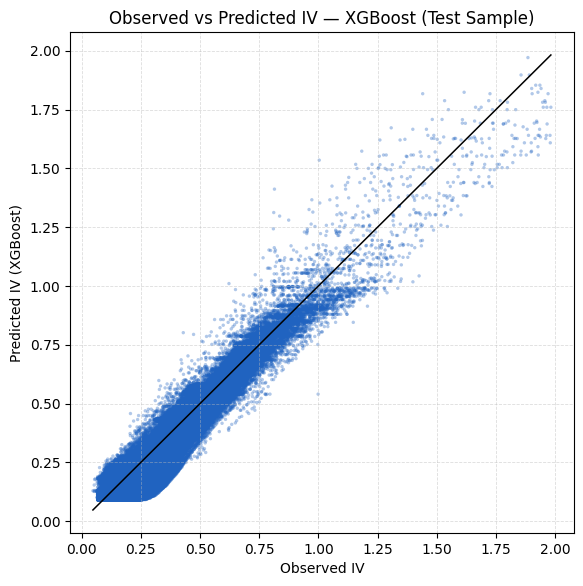

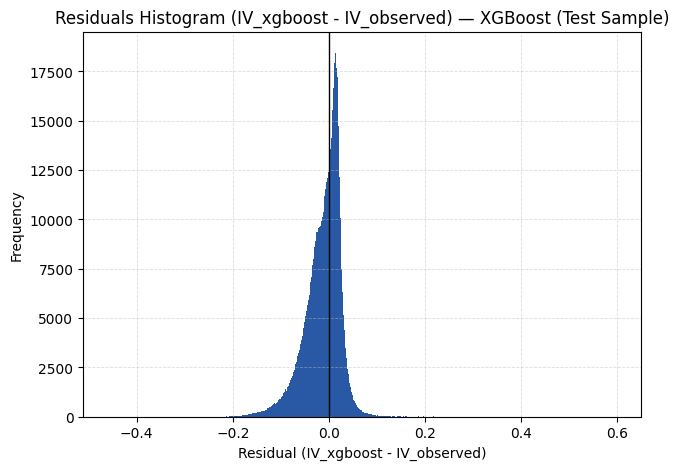

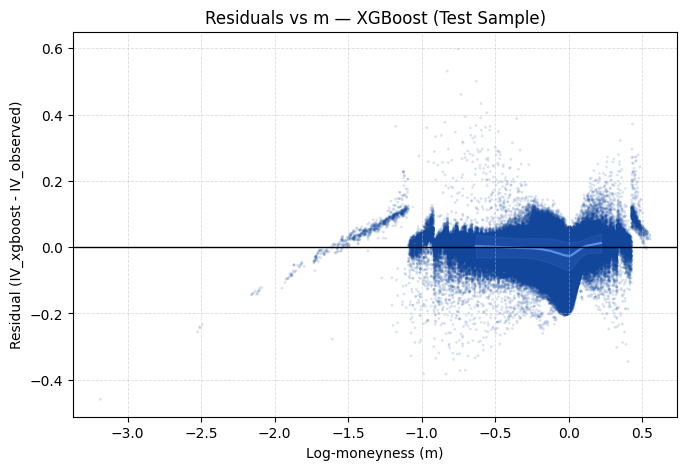

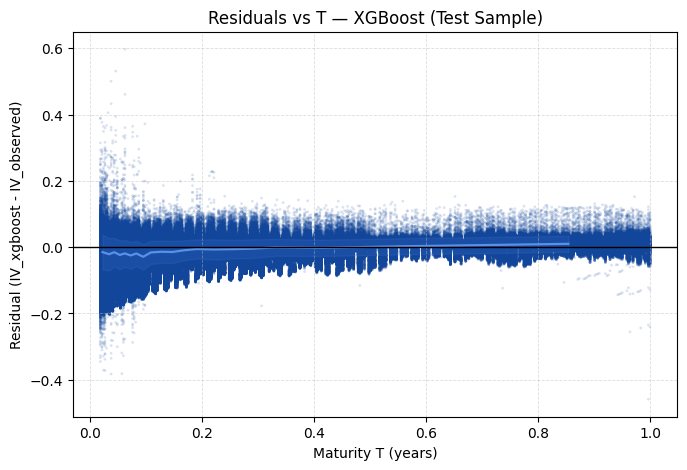

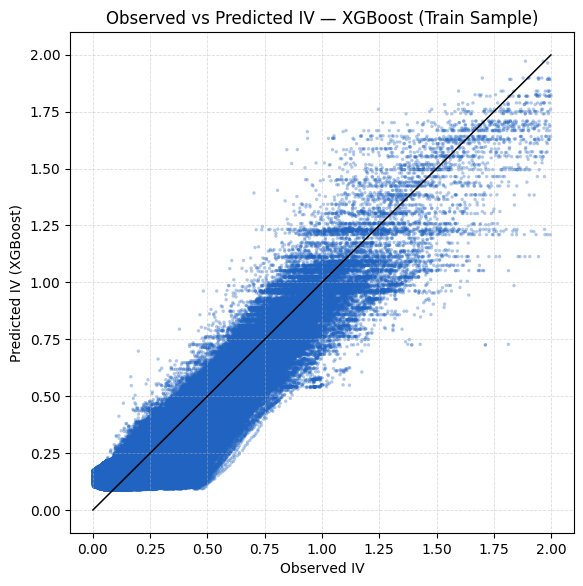

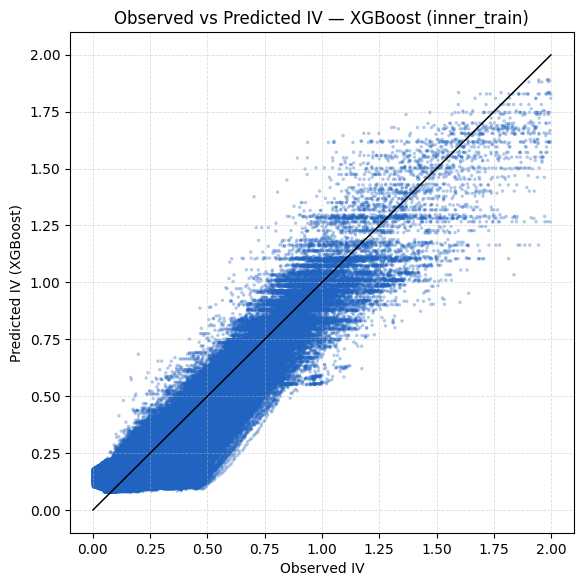

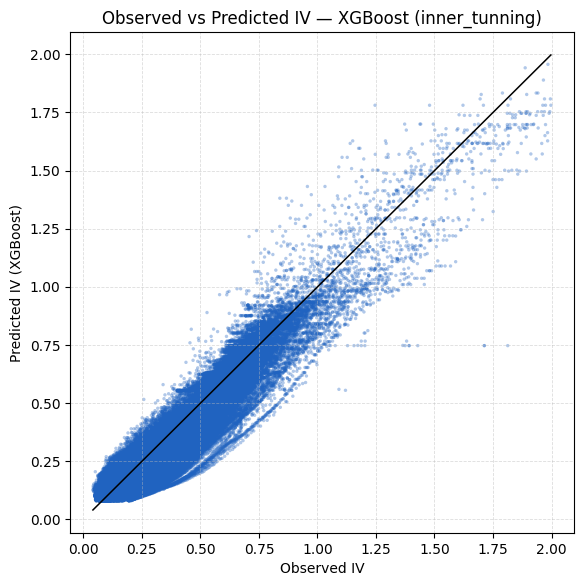

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,XGBoost,test_puro,geral,train_full,1292514,0.041170,0.029317,0.019887,0.875123,-1.575035e-02
1,XGBoost,train_full,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
2,XGBoost,Test Sample,geral,train_full,1292514,0.038799,0.027982,0.019900,0.889093,-1.170406e-02
3,XGBoost,Train Sample,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
4,XGBoost,inner_train,especifica,inner_training,5970843,0.045481,0.031175,0.022980,0.866874,-1.323001e-07
5,XGBoost,inner_tunning,especifica,inner_training,1534395,0.035321,0.025793,0.021230,0.920560,4.126067e-03


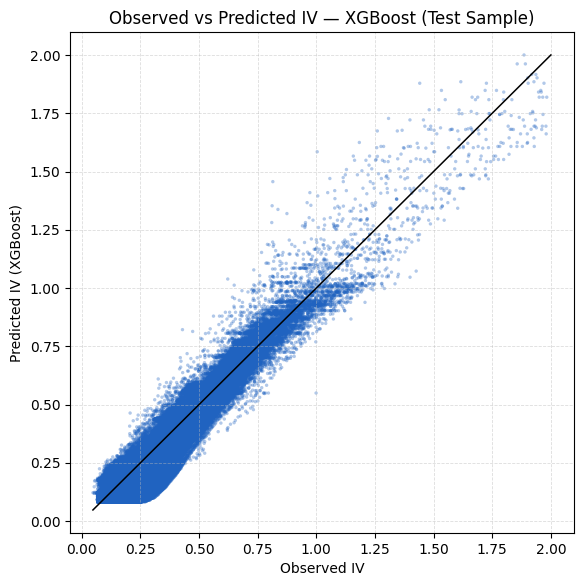

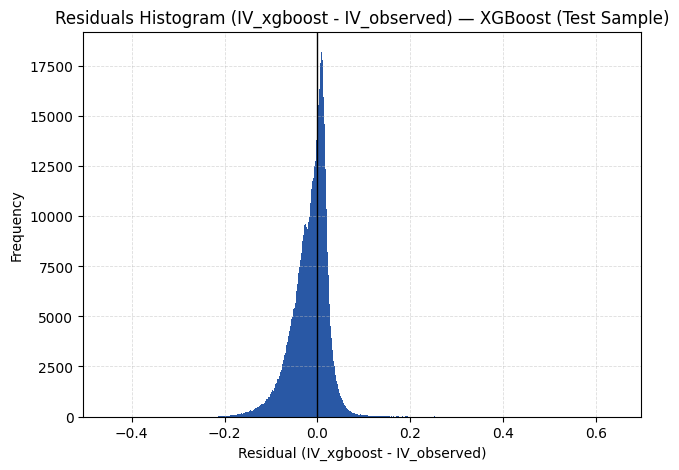

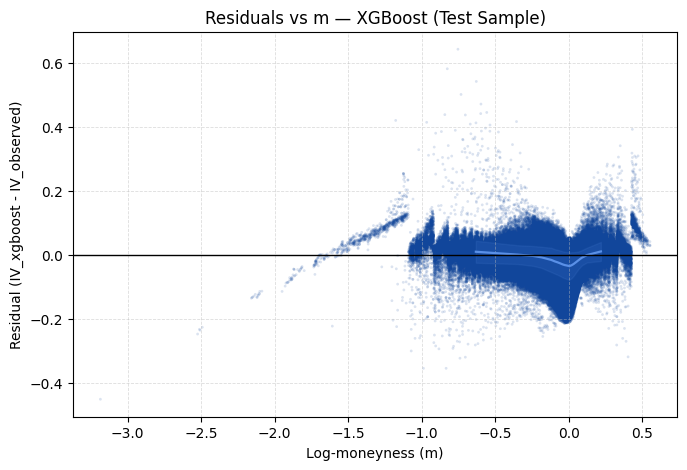

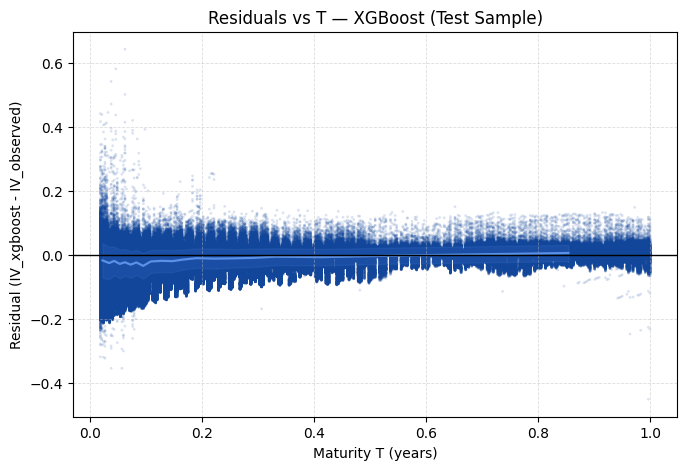

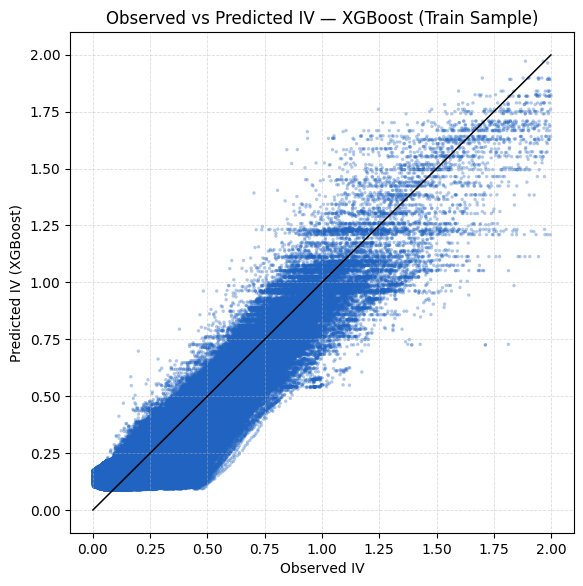

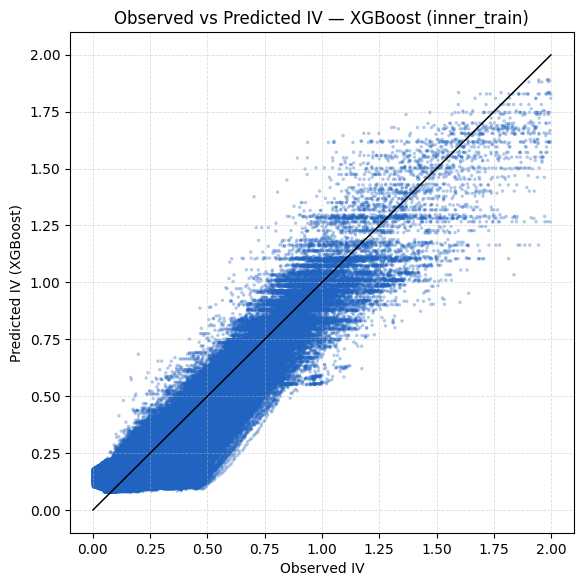

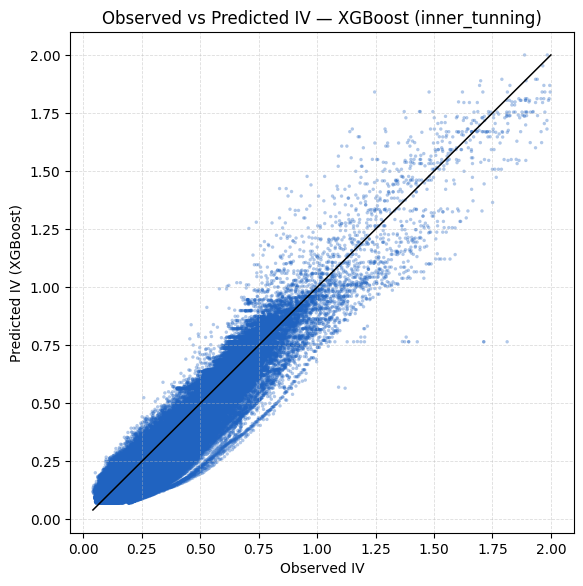

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,XGBoost,test_puro,geral,train_full,1292514,0.041170,0.029317,0.019887,0.875123,-1.575035e-02
1,XGBoost,train_full,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
2,XGBoost,Test Sample,geral,train_full,1292514,0.041170,0.029317,0.019887,0.875123,-1.575035e-02
3,XGBoost,Train Sample,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
4,XGBoost,inner_train,especifica,inner_training,5970843,0.045481,0.031175,0.022980,0.866874,-1.323001e-07
5,XGBoost,inner_tunning,especifica,inner_training,1534395,0.034764,0.024342,0.018333,0.923047,-5.149797e-09


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,XGBoost,test_puro,geral,train_full,1292514,0.041170,0.029317,0.019887,0.875123,-1.575035e-02
1,XGBoost,train_full,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
2,XGBoost,Test Sample,geral,train_full,1292514,0.041170,0.029317,0.019887,0.875123,-1.575035e-02
3,XGBoost,Train Sample,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
4,XGBoost,inner_train,especifica,inner_training,5970843,0.045481,0.031175,0.022980,0.866874,-1.323001e-07


In [14]:
# --- 1) Run evaluation for uncalibrated model ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="XGBoost",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

# --- 2) Run evaluation for calibrated model ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred_cal,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred_cal,
    model="XGBoost",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

### 11. 3D Volatility Surface & Residual Diagnostics


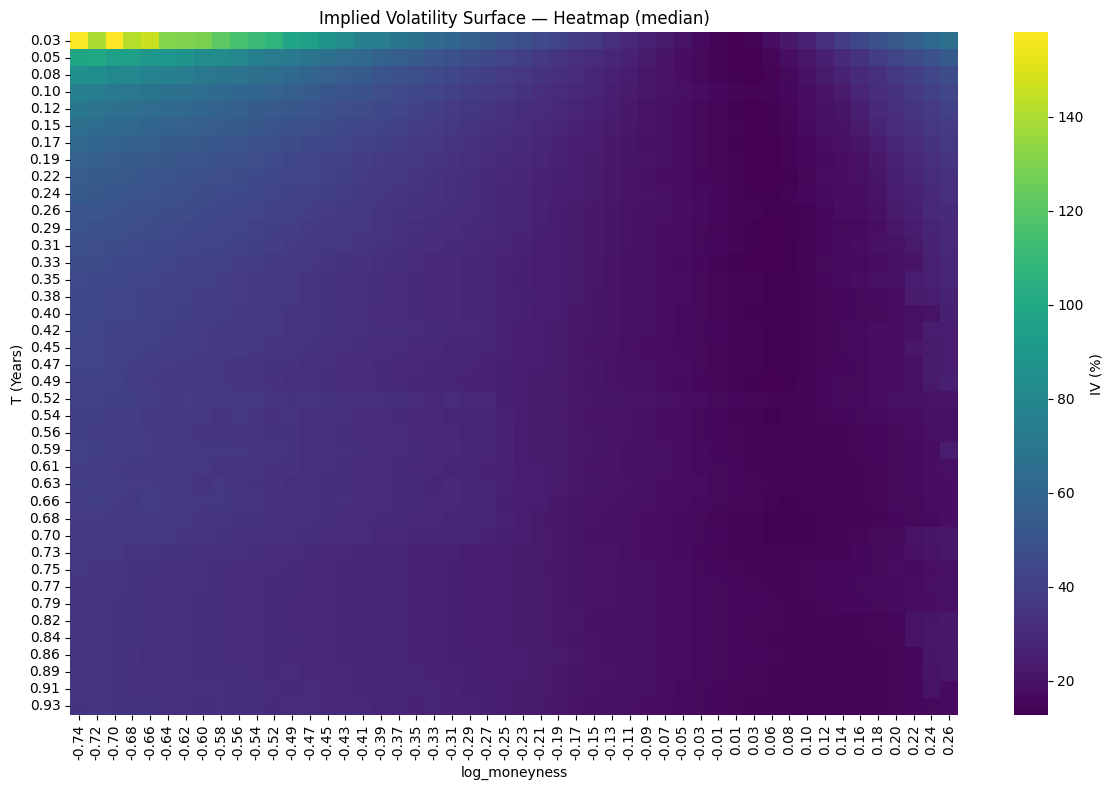

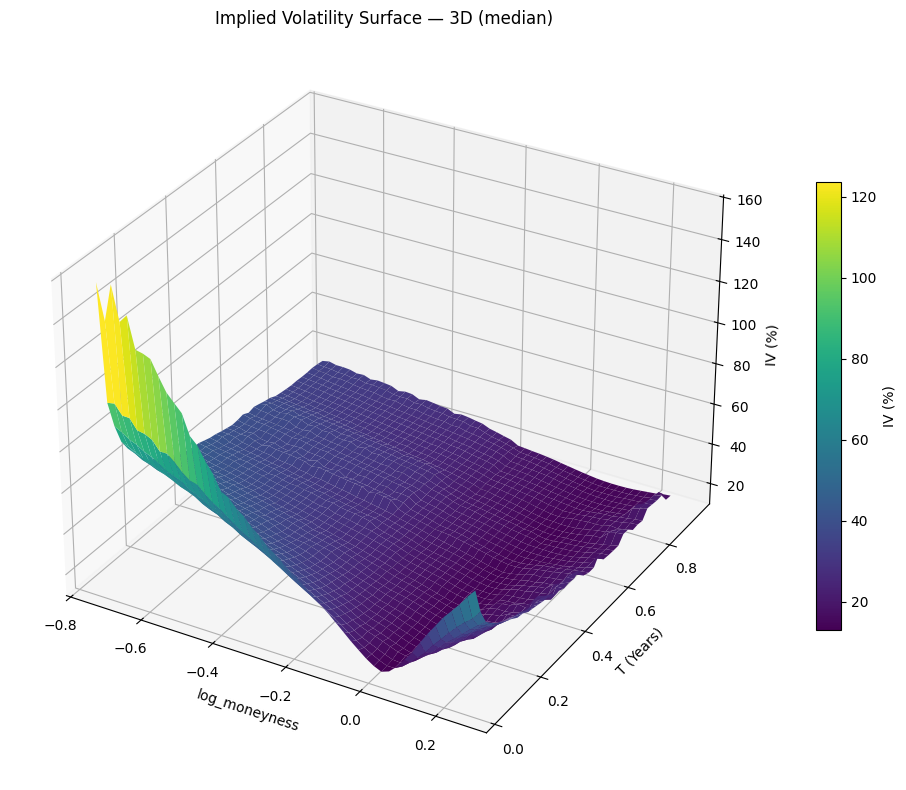

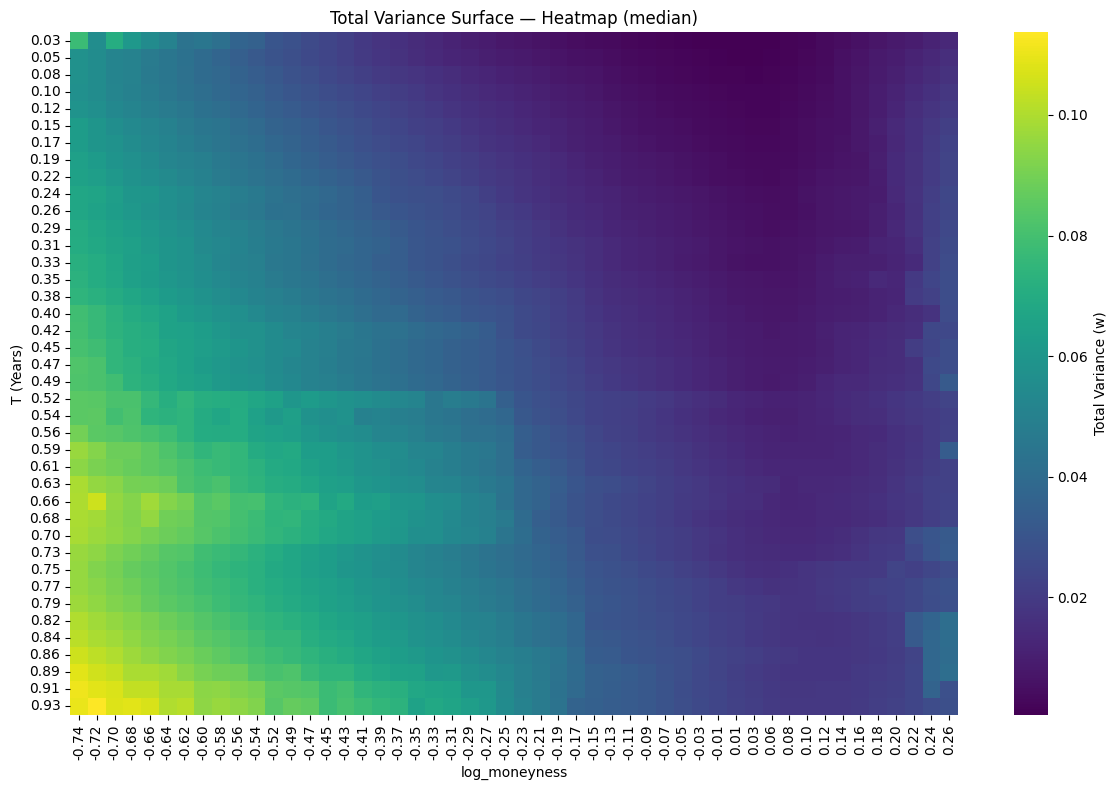

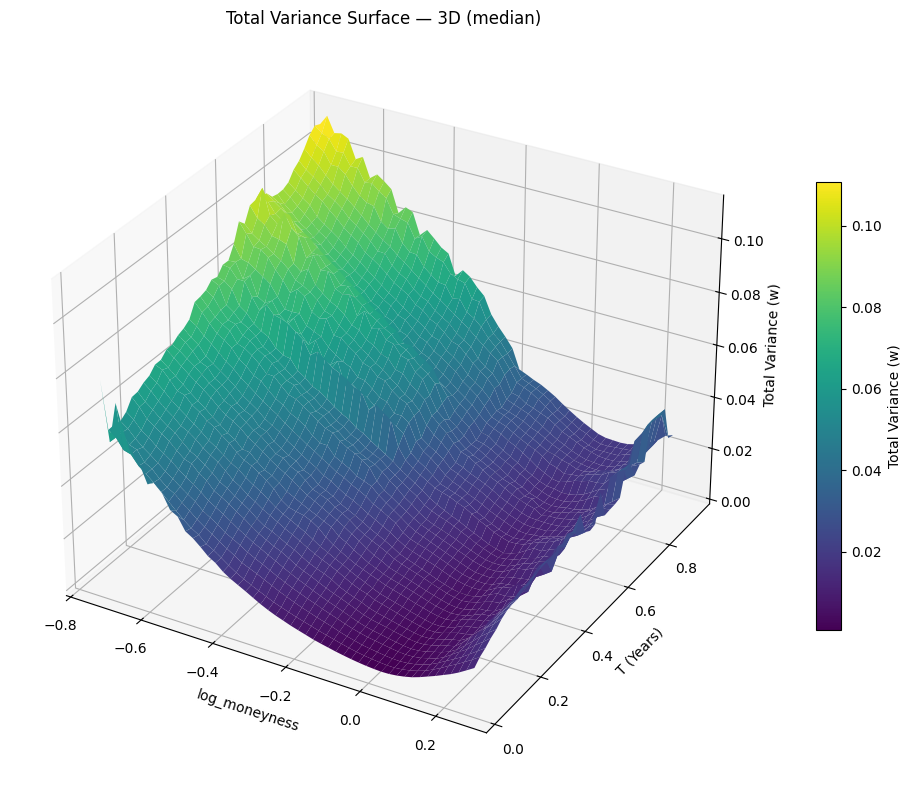

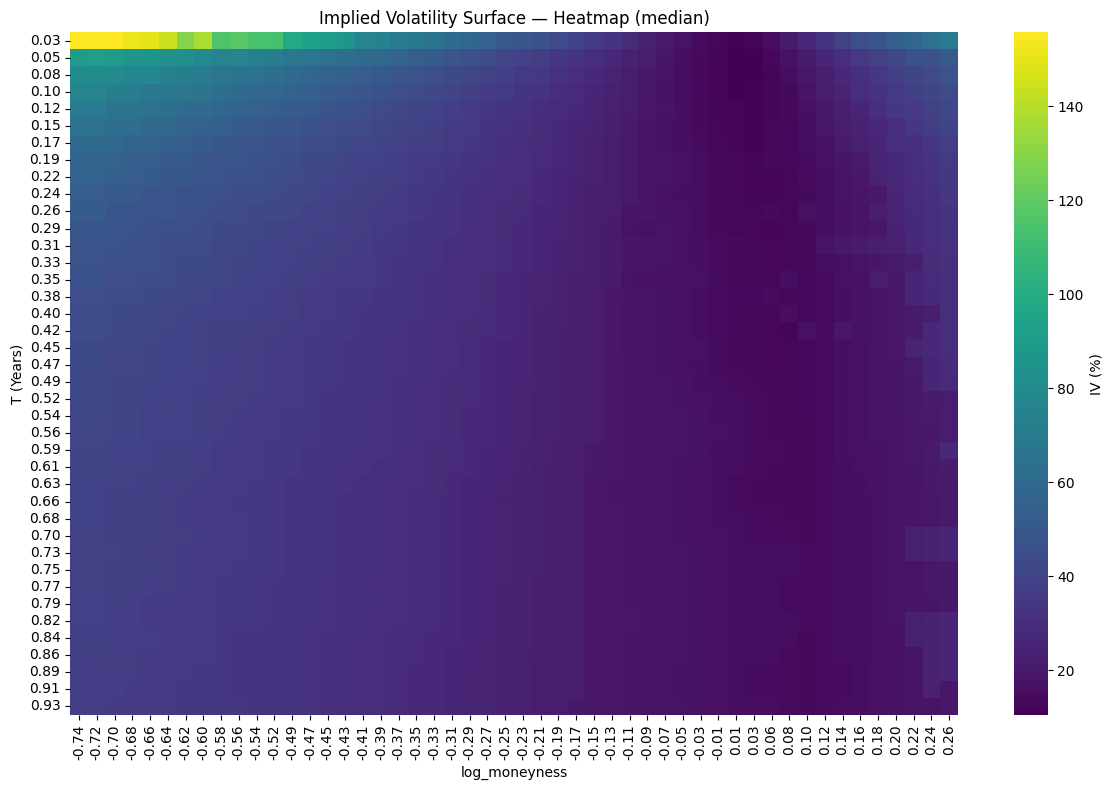

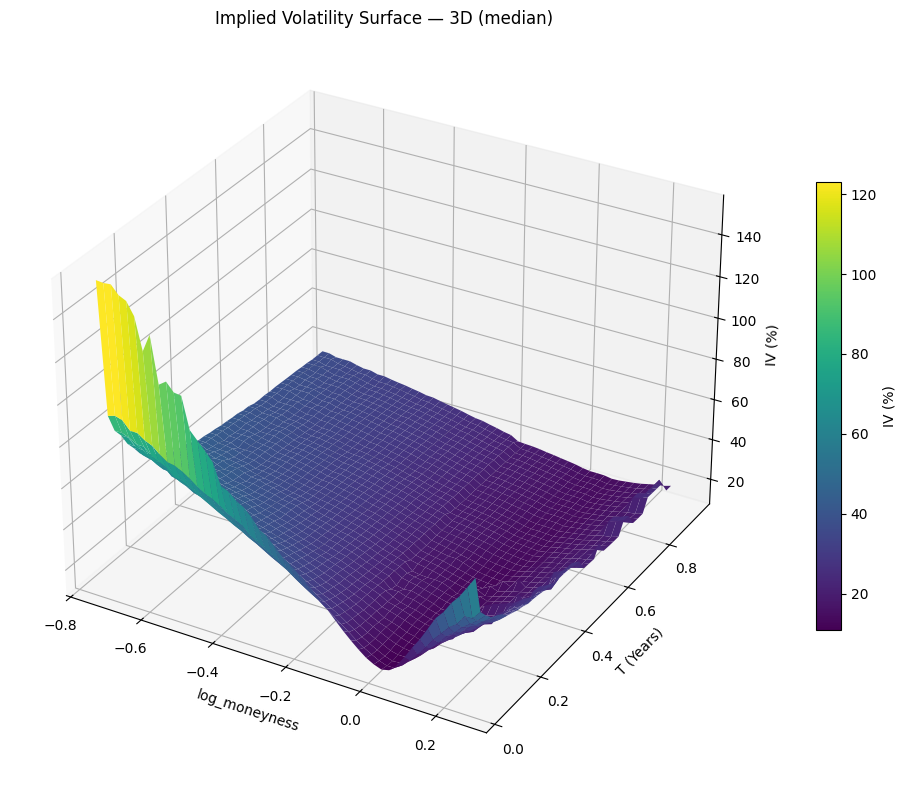

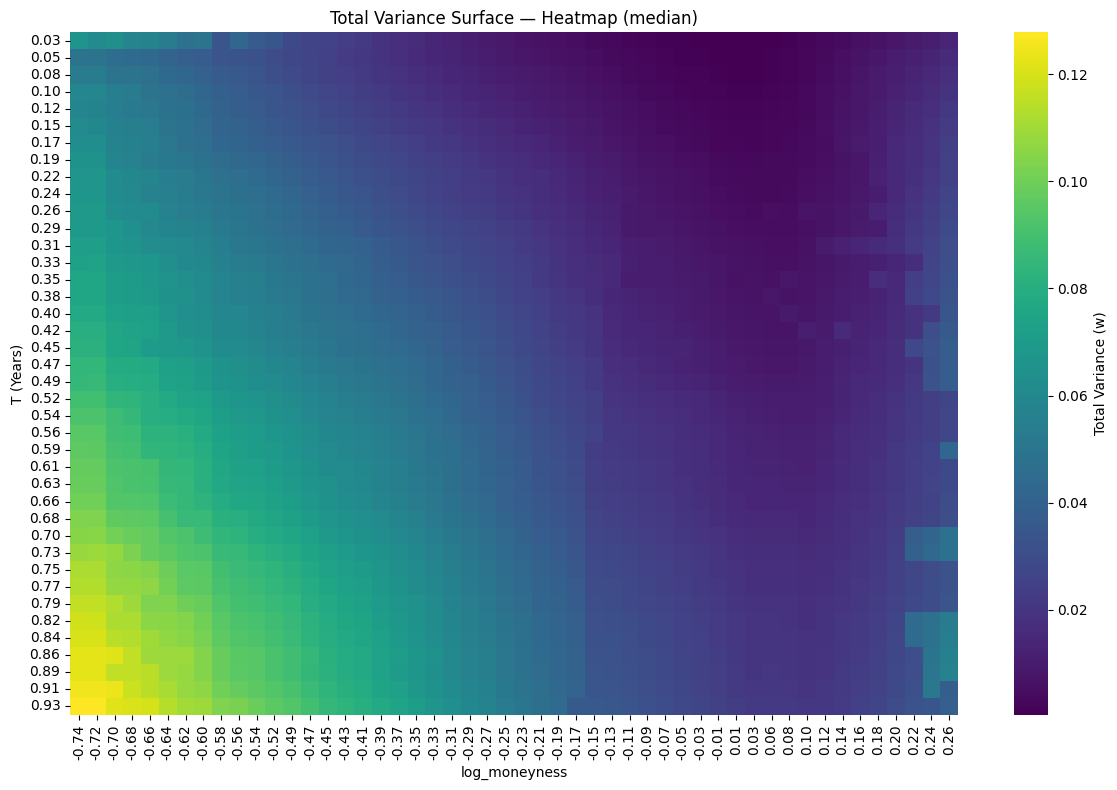

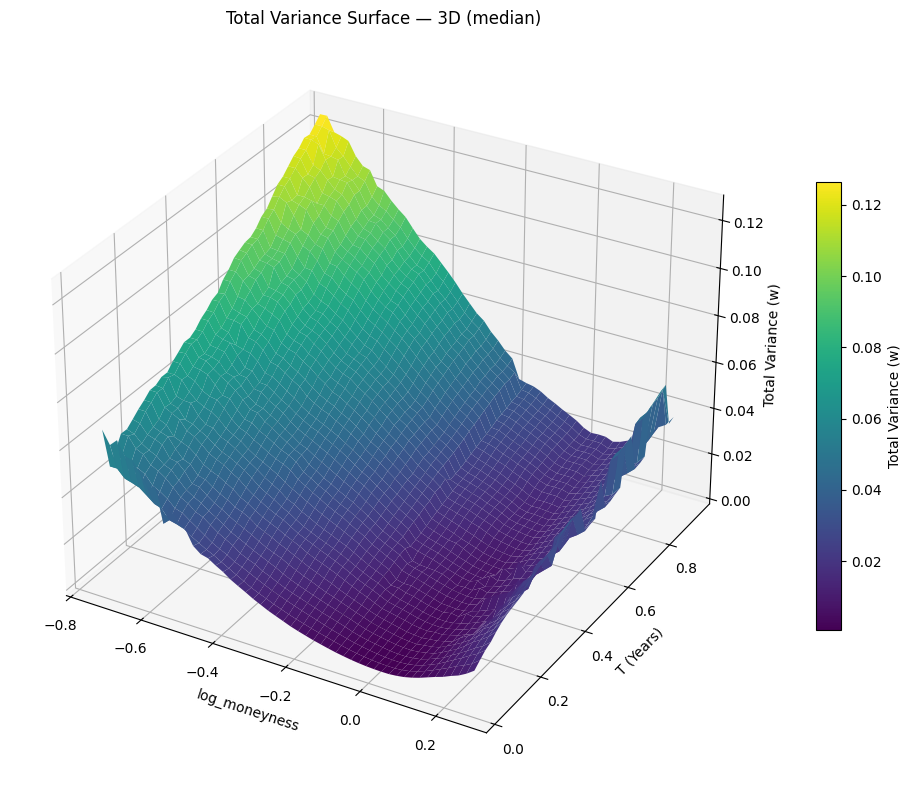

In [15]:
# 1) Theoretical surface
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
)

# 2) Model implied volatility surface (uncalibrated)
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
)

# # 3) Model implied volatility surface (calibrated)
# plot_ivs_and_variance_surfaces(
#     df_test_puro_pred_cal,
#     x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
#     agg="median",
#     nbins_x=50, nbins_y=40,
#     save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
# )